In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_excel("Movie_Dataset_Sample.xlsx")
df.head()

,Movie_ID,Title,Genre,Release_Year,Rating,Votes,Runtime_Minutes,Revenue_Million_USD
0,MOV001,The Last Journey,Thriller,2009,8.2,140536,128,37.35
1,MOV002,City Lights,Romance,2002,4.5,111294,152,599.20
2,MOV003,Beyond the Stars,Animation,2009,4.5,146030,128,124.25
3,MOV004,Silent River,Sci-Fi,2020,6.7,224619,156,684.25
4,MOV005,The Hidden Truth,Drama,2006,8.0,145338,130,370.80


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40 entries, 0 to 39
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Movie_ID             40 non-null     object 
 1   Title                40 non-null     object 
 2   Genre                40 non-null     object 
 3   Release_Year         40 non-null     int64  
 4   Rating               40 non-null     float64
 5   Votes                40 non-null     int64  
 6   Runtime_Minutes      40 non-null     int64  
 7   Revenue_Million_USD  40 non-null     float64
dtypes: float64(2), int64(3), object(3)
memory usage: 2.6+ KB


In [4]:
df.shape

(40, 8)

In [5]:
df.columns

Index(['Movie_ID', 'Title', 'Genre', 'Release_Year', 'Rating', 'Votes',
       'Runtime_Minutes', 'Revenue_Million_USD'],
      dtype='object')

In [6]:
df.isnull().sum()

Movie_ID               0
Title                  0
Genre                  0
Release_Year           0
Rating                 0
Votes                  0
Runtime_Minutes        0
Revenue_Million_USD    0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df = df.drop_duplicates()
df = df.dropna()

df["Release_Year"] = df["Release_Year"].astype(int)
df["Rating"] = df["Rating"].astype(float)

df.head()

,Movie_ID,Title,Genre,Release_Year,Rating,Votes,Runtime_Minutes,Revenue_Million_USD
0,MOV001,The Last Journey,Thriller,2009,8.2,140536,128,37.35
1,MOV002,City Lights,Romance,2002,4.5,111294,152,599.20
2,MOV003,Beyond the Stars,Animation,2009,4.5,146030,128,124.25
3,MOV004,Silent River,Sci-Fi,2020,6.7,224619,156,684.25
4,MOV005,The Hidden Truth,Drama,2006,8.0,145338,130,370.80


In [9]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())
print("\nDataset Shape:", df.shape)

Missing Values:
Movie_ID               0
Title                  0
Genre                  0
Release_Year           0
Rating                 0
Votes                  0
Runtime_Minutes        0
Revenue_Million_USD    0
dtype: int64

Duplicate Rows: 0

Dataset Shape: (40, 8)


In [10]:
df.describe()


,Release_Year,Rating,Votes,Runtime_Minutes,Revenue_Million_USD
count,40.000000,40.00000,40.000000,40.000000,40.000000
mean,2012.850000,6.72500,118491.375000,130.275000,430.536000
std,8.266553,1.33104,69576.219802,27.922041,251.810132
min,2001.000000,4.20000,2798.000000,81.000000,6.880000
25%,2006.750000,5.60000,68584.000000,110.000000,216.265000
50%,2012.000000,6.60000,110816.000000,131.500000,435.560000
75%,2021.000000,8.00000,164196.500000,154.500000,645.880000
max,2025.000000,9.00000,244596.000000,179.000000,877.470000


In [11]:
top_rated_movies = df.sort_values(by="Rating", ascending=False).head(10)

top_rated_movies[["Title", "Genre", "Rating"]]

,Title,Genre,Rating
32,Starbound,Drama,9.0
17,Echoes of Tomorrow,Adventure,8.9
0,The Last Journey,Thriller,8.2
34,The Last Signal,Romance,8.2
14,Broken Promise,Comedy,8.2
11,Summer Memories,Action,8.1
24,Mystery Lane,Romance,8.1
31,The Long Road,Drama,8.1
30,Hidden Figures,Comedy,8.0
10,Lost Kingdom,Drama,8.0


In [12]:
average_rating = df["Rating"].mean()

print("Average Movie Rating:", round(average_rating, 2))

Average Movie Rating: 6.72


In [13]:
genre_counts = df["Genre"].value_counts()

print(genre_counts)

Genre
Drama        8
Comedy       6
Thriller     5
Romance      5
Sci-Fi       5
Animation    5
Action       4
Adventure    2
Name: count, dtype: int64


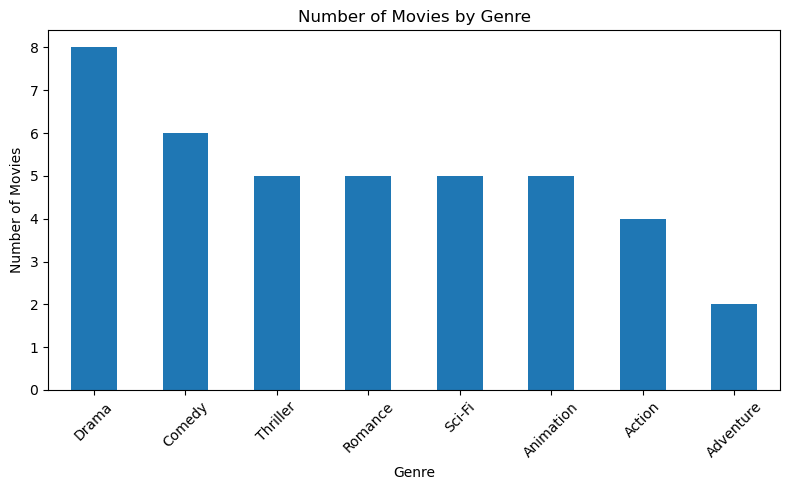

In [14]:
genre_counts.plot(kind="bar", figsize=(8, 5))

plt.title("Number of Movies by Genre")
plt.xlabel("Genre")
plt.ylabel("Number of Movies")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [15]:
genre_ratings = df.groupby("Genre")["Rating"].mean().sort_values(ascending=False)

print(genre_ratings.round(2))

Genre
Adventure    7.70
Action       7.10
Comedy       7.00
Drama        6.88
Romance      6.78
Sci-Fi       6.56
Thriller     6.32
Animation    5.98
Name: Rating, dtype: float64


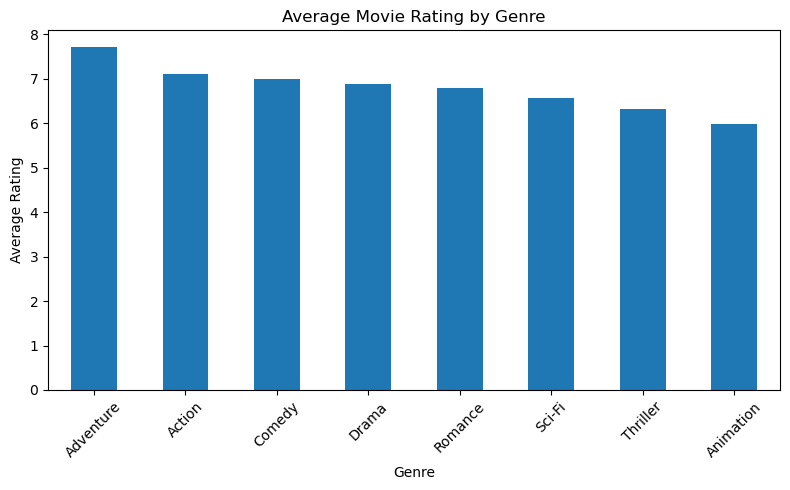

In [16]:
genre_ratings.plot(kind="bar", figsize=(8, 5))

plt.title("Average Movie Rating by Genre")
plt.xlabel("Genre")
plt.ylabel("Average Rating")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [17]:
total_revenue = df["Revenue_Million_USD"].sum()
average_revenue = df["Revenue_Million_USD"].mean()

print("Total Revenue (Million USD):", round(total_revenue, 2))
print("Average Revenue (Million USD):", round(average_revenue, 2))

Total Revenue (Million USD): 17221.44
Average Revenue (Million USD): 430.54


In [18]:
top_revenue = df.sort_values(
    by="Revenue_Million_USD",
    ascending=False
).head(10)

top_revenue[["Title", "Revenue_Million_USD", "Rating"]]

,Title,Revenue_Million_USD,Rating
31,The Long Road,877.47,8.1
13,A New Beginning,798.21,5.4
26,Dark Matter,759.95,6.5
10,Lost Kingdom,746.34,8.0
36,Parallel Worlds,701.11,5.3
3,Silent River,684.25,6.7
6,Midnight Chase,677.02,5.5
30,Hidden Figures,666.05,8.0
33,Paper Wings,666.02,4.2
16,The Time Traveler,646.54,4.7


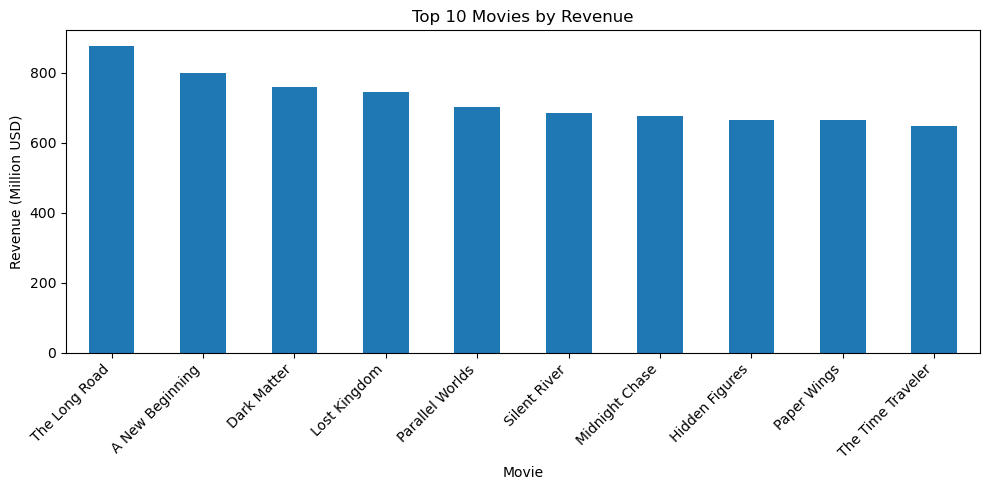

In [19]:
top_revenue.plot(
    x="Title",
    y="Revenue_Million_USD",
    kind="bar",
    figsize=(10, 5),
    legend=False
)

plt.title("Top 10 Movies by Revenue")
plt.xlabel("Movie")
plt.ylabel("Revenue (Million USD)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

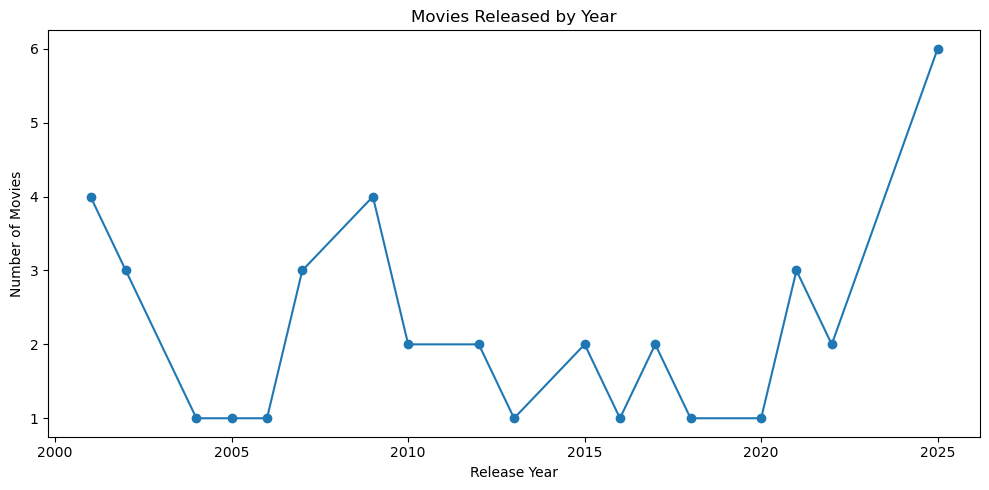

In [20]:
year_counts = df["Release_Year"].value_counts().sort_index()

year_counts.plot(kind="line", marker="o", figsize=(10, 5))

plt.title("Movies Released by Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Movies")
plt.tight_layout()
plt.show()

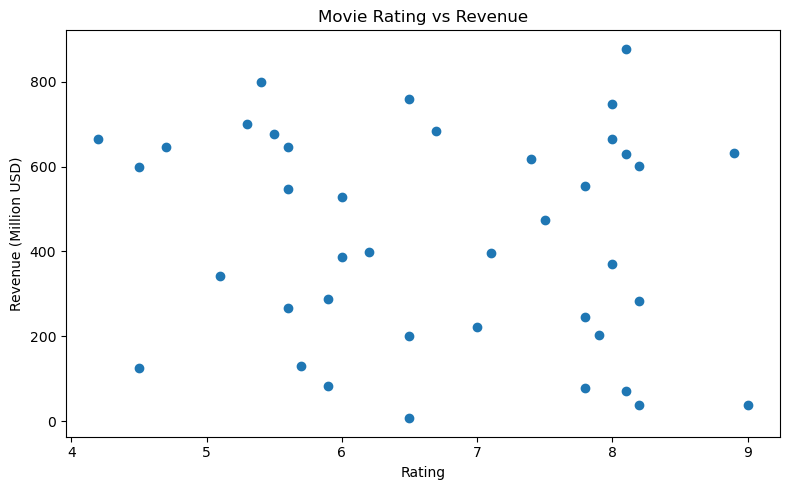

In [21]:
plt.figure(figsize=(8, 5))

plt.scatter(df["Rating"], df["Revenue_Million_USD"])

plt.title("Movie Rating vs Revenue")
plt.xlabel("Rating")
plt.ylabel("Revenue (Million USD)")
plt.tight_layout()
plt.show()

In [22]:
numeric_columns = [
    "Release_Year",
    "Rating",
    "Votes",
    "Runtime_Minutes",
    "Revenue_Million_USD"
]

correlation = df[numeric_columns].corr()

print(correlation.round(2))

                     Release_Year  Rating  Votes  Runtime_Minutes  \
Release_Year                 1.00    0.19   0.17            -0.06   
Rating                       0.19    1.00   0.15             0.06   
Votes                        0.17    0.15   1.00            -0.06   
Runtime_Minutes             -0.06    0.06  -0.06             1.00   
Revenue_Million_USD         -0.12   -0.14  -0.18             0.20   

                     Revenue_Million_USD  
Release_Year                       -0.12  
Rating                             -0.14  
Votes                              -0.18  
Runtime_Minutes                     0.20  
Revenue_Million_USD                 1.00  


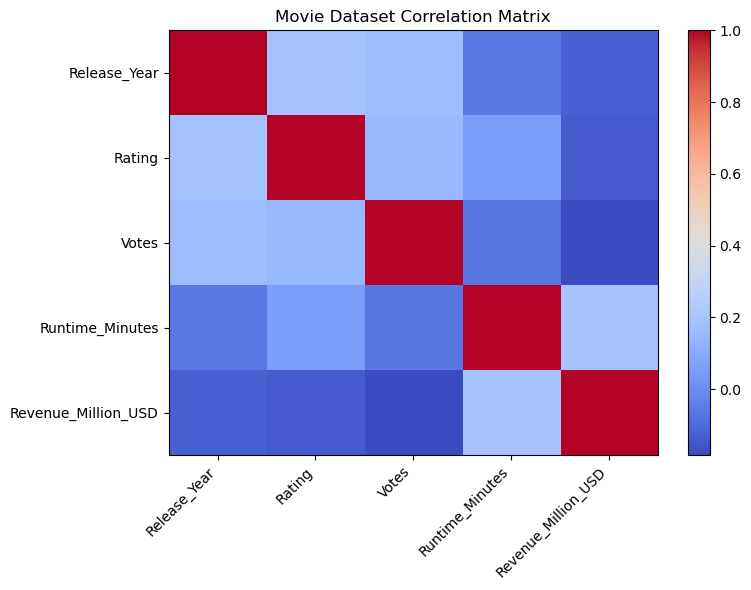

In [23]:
plt.figure(figsize=(8, 6))

plt.imshow(correlation, cmap="coolwarm", aspect="auto")
plt.colorbar()

plt.xticks(range(len(correlation.columns)), correlation.columns, rotation=45, ha="right")
plt.yticks(range(len(correlation.columns)), correlation.columns)

plt.title("Movie Dataset Correlation Matrix")
plt.tight_layout()
plt.show()

In [24]:
best_rated = df.loc[df["Rating"].idxmax()]
highest_revenue = df.loc[df["Revenue_Million_USD"].idxmax()]
most_voted = df.loc[df["Votes"].idxmax()]
most_common_genre = df["Genre"].mode()[0]

print("MOVIE DATASET INSIGHTS")
print("----------------------")
print("Total Movies:", len(df))
print("Average Rating:", round(df["Rating"].mean(), 2))
print("Most Common Genre:", most_common_genre)
print("Highest Rated Movie:", best_rated["Title"])
print("Highest Rating:", best_rated["Rating"])
print("Highest Revenue Movie:", highest_revenue["Title"])
print("Highest Revenue:", highest_revenue["Revenue_Million_USD"], "Million USD")
print("Most Voted Movie:", most_voted["Title"])
print("Highest Votes:", most_voted["Votes"])

MOVIE DATASET INSIGHTS
----------------------
Total Movies: 40
Average Rating: 6.72
Most Common Genre: Drama
Highest Rated Movie: Starbound
Highest Rating: 9.0
Highest Revenue Movie: The Long Road
Highest Revenue: 877.47 Million USD
Most Voted Movie: Dream Makers
Highest Votes: 244596


In [25]:
assert not df.empty, "Dataset is empty"
assert df.isnull().sum().sum() == 0, "Missing values found"
assert df.duplicated().sum() == 0, "Duplicate rows found"
assert df["Rating"].between(0, 10).all(), "Invalid ratings found"
assert (df["Votes"] >= 0).all(), "Invalid vote counts found"
assert (df["Revenue_Million_USD"] >= 0).all(), "Invalid revenue values found"

print("All data validation tests passed!")

All data validation tests passed!


In [26]:
df.to_excel("Cleaned_Movie_Dataset.xlsx", index=False)

print("Cleaned dataset exported successfully!")

Cleaned dataset exported successfully!


In [27]:
report = f"""
MOVIE DATASET ANALYSIS REPORT

1. PROJECT OVERVIEW
This project analyzes movie data using Python, Pandas and Matplotlib.

2. DATASET SUMMARY
Total Movies: {len(df)}
Total Columns: {len(df.columns)}
Average Rating: {df["Rating"].mean():.2f}
Average Runtime: {df["Runtime_Minutes"].mean():.2f} minutes
Average Revenue: {df["Revenue_Million_USD"].mean():.2f} million USD

3. KEY FINDINGS
Most Common Genre: {df["Genre"].mode()[0]}
Highest Rated Movie: {df.loc[df["Rating"].idxmax(), "Title"]}
Highest Revenue Movie: {df.loc[df["Revenue_Million_USD"].idxmax(), "Title"]}
Most Voted Movie: {df.loc[df["Votes"].idxmax(), "Title"]}

4. DATA QUALITY
Missing Values: {df.isnull().sum().sum()}
Duplicate Rows: {df.duplicated().sum()}

5. CONCLUSION
The analysis explores movie ratings, genres, revenue, release years,
votes and relationships between numerical variables.

IMPORTANT:
This project uses a sample dataset for demonstration.
The results should not be treated as verified real-world movie statistics.
"""

with open("Movie_Analysis_Report.txt", "w", encoding="utf-8") as file:
    file.write(report)

print(report)
print("Report saved successfully!")


MOVIE DATASET ANALYSIS REPORT

1. PROJECT OVERVIEW
This project analyzes movie data using Python, Pandas and Matplotlib.

2. DATASET SUMMARY
Total Movies: 40
Total Columns: 8
Average Rating: 6.72
Average Runtime: 130.28 minutes
Average Revenue: 430.54 million USD

3. KEY FINDINGS
Most Common Genre: Drama
Highest Rated Movie: Starbound
Highest Revenue Movie: The Long Road
Most Voted Movie: Dream Makers

4. DATA QUALITY
Missing Values: 0
Duplicate Rows: 0

5. CONCLUSION
The analysis explores movie ratings, genres, revenue, release years,
votes and relationships between numerical variables.

IMPORTANT:
This project uses a sample dataset for demonstration.
The results should not be treated as verified real-world movie statistics.

Report saved successfully!


In [28]:
import os

for file in os.listdir():
    if file.endswith((".xlsx", ".txt", ".ipynb")):
        print(file)

Cleaned_Movie_Dataset.xlsx
COVID_19_Data_Analysis.ipynb
COVID_19_Sample_Data.xlsx
customer_segmentation.xlsx
Customer_Segmentation_200_Rows.xlsx
member2_data_preprocessing_EDA.ipynb
Movie_Analysis_Report.txt
Movie_Dataset_Analysis.ipynb
Movie_Dataset_Sample.xlsx
Netflix_Analysis.ipynb
Retail_Analytics.ipynb
Retail_Analytics_Sample_Data (1).xlsx
Retail_Analytics_Sample_Data.xlsx
Sales_Data_Analysis_Dashboard.ipynb
student_Performance_Analysis.ipynb
Student_Performance_Sample_Data.xlsx
tuple (1).ipynb
Untitled.ipynb
Untitled1.ipynb
Untitled2.ipynb
